In [1]:
import sys, os, tempfile
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

from src.data import load_data, get_column_types, RISK_ORDER
from src.preprocessing import prepare_data, RANDOM_STATE
from src.models import train_models
from src.tuning import tune_models, CV, SCORING, LOGREG_GRID, GB_PARAMS, N_ITER

In [2]:
X_train, X_test, y_train, y_test = prepare_data(load_data())
base, _ = train_models(X_train, X_test, y_train, y_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("CV:", CV.n_splits, "folds, stratified | scoring:", SCORING)

Train: (1570, 15) | Test: (393, 15)
CV: 5 folds, stratified | scoring: f1_macro


In [3]:
rows = {}
for name, pipe in base.items():
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1).mean()
    train_f1 = f1_score(y_train, pipe.predict(X_train), average="macro")
    rows[name] = {"cv_f1": cv_f1, "train_f1": train_f1, "gap": train_f1 - cv_f1}
baseline = pd.DataFrame(rows).T
baseline.round(3)

,cv_f1,train_f1,gap
LogisticRegression,0.741,0.759,0.018
RandomForest,0.678,1.000,0.322
GradientBoosting,0.697,0.903,0.207


In [4]:
SELECTED = ["LogisticRegression", "GradientBoosting"]
SELECTED

['LogisticRegression', 'GradientBoosting']

In [5]:
print(LOGREG_GRID)
grid = GridSearchCV(base["LogisticRegression"], LOGREG_GRID, scoring=SCORING, cv=CV,
                    n_jobs=-1, return_train_score=True).fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_)[["param_model__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(3)

{'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]}
Best params: {'model__C': 3}
Best CV F1: 0.744


,param_model__C,mean_train_score,mean_test_score,std_test_score
0,0.01,0.725,0.702,0.025
1,0.03,0.747,0.732,0.014
2,0.10,0.761,0.739,0.008
3,0.30,0.761,0.738,0.010
4,1.00,0.761,0.741,0.009
5,3.00,0.759,0.744,0.010
6,10.00,0.760,0.744,0.010
7,30.00,0.760,0.744,0.010
8,100.00,0.760,0.744,0.010


In [6]:
print(GB_PARAMS)
rand = RandomizedSearchCV(base["GradientBoosting"], GB_PARAMS, n_iter=N_ITER, scoring=SCORING, cv=CV,
                          n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True).fit(X_train, y_train)

print("Best params:", rand.best_params_)
print("Best CV F1:", round(rand.best_score_, 3))
res = pd.DataFrame(rand.cv_results_).sort_values("rank_test_score")
res[[c for c in res.columns if c.startswith("param_")] + ["mean_train_score", "mean_test_score", "std_test_score"]].head(10).round(3)

{'model__n_estimators': [50, 100, 200, 300], 'model__learning_rate': [0.01, 0.05, 0.1, 0.2], 'model__max_depth': [2, 3, 4], 'model__min_samples_leaf': [1, 5, 10, 20], 'model__subsample': [0.7, 0.85, 1.0]}
Best params: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best CV F1: 0.708


,param_model__subsample,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_depth,param_model__learning_rate,mean_train_score,mean_test_score,std_test_score
0,0.70,200,20,3,0.05,0.907,0.708,0.016
13,1.00,200,5,3,0.10,0.974,0.706,0.019
4,0.70,200,5,4,0.10,1.000,0.701,0.025
11,0.70,100,5,2,0.20,0.881,0.700,0.022
19,0.70,300,1,2,0.05,0.869,0.700,0.016
9,1.00,200,20,3,0.10,0.962,0.700,0.011
6,0.85,200,5,4,0.05,0.985,0.696,0.020
27,1.00,100,20,4,0.10,0.968,0.695,0.020
20,0.85,50,20,4,0.20,0.963,0.695,0.017
26,0.85,200,1,4,0.05,0.988,0.694,0.018


In [7]:
tuned = {"LogisticRegression": grid, "GradientBoosting": rand}

comp = pd.DataFrame({
    name: {
        "cv_f1_default": baseline.loc[name, "cv_f1"],
        "cv_f1_tuned": s.best_score_,
        "cv_std_tuned": s.cv_results_["std_test_score"][s.best_index_],
        "train_f1_tuned": f1_score(y_train, s.best_estimator_.predict(X_train), average="macro"),
    } for name, s in tuned.items()
}).T
comp["gap_tuned"] = comp["train_f1_tuned"] - comp["cv_f1_tuned"]
comp.round(3)

,cv_f1_default,cv_f1_tuned,cv_std_tuned,train_f1_tuned,gap_tuned
LogisticRegression,0.741,0.744,0.010,0.758,0.014
GradientBoosting,0.697,0.708,0.016,0.887,0.179


In [8]:
oof = {n: cross_val_predict(s.best_estimator_, X_train, y_train, cv=CV, n_jobs=-1) for n, s in tuned.items()}
HIGH, MEDIUM = RISK_ORDER.index("High"), RISK_ORDER.index("Medium")

pd.DataFrame({
    n: {"oof_f1": f1_score(y_train, p, average="macro"),
        "oof_recall_High": recall_score(y_train, p, labels=[HIGH], average=None)[0],
        "oof_recall_Medium": recall_score(y_train, p, labels=[MEDIUM], average=None)[0]}
    for n, p in oof.items()
}).T.round(3)

,oof_f1,oof_recall_High,oof_recall_Medium
LogisticRegression,0.745,0.810,0.632
GradientBoosting,0.708,0.799,0.570


In [9]:
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_pipeline = tuned[best_name].best_estimator_
print("Chosen (highest CV F1):", best_name)

Chosen (highest CV F1): LogisticRegression


In [10]:
pred = best_pipeline.predict(X_test)
proba = best_pipeline.predict_proba(X_test)

print({
    "accuracy": round(accuracy_score(y_test, pred), 3),
    "precision": round(precision_score(y_test, pred, average="macro"), 3),
    "recall": round(recall_score(y_test, pred, average="macro"), 3),
    "f1": round(f1_score(y_test, pred, average="macro"), 3),
    "roc_auc": round(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), 3),
})
print(classification_report(y_test, pred, target_names=RISK_ORDER, digits=3))

{'accuracy': 0.784, 'precision': 0.784, 'recall': 0.783, 'f1': 0.783, 'roc_auc': 0.924}
              precision    recall  f1-score   support

         Low      0.835     0.854     0.844       130
      Medium      0.667     0.682     0.674       129
        High      0.852     0.813     0.832       134

    accuracy                          0.784       393
   macro avg      0.784     0.783     0.783       393
weighted avg      0.785     0.784     0.784       393



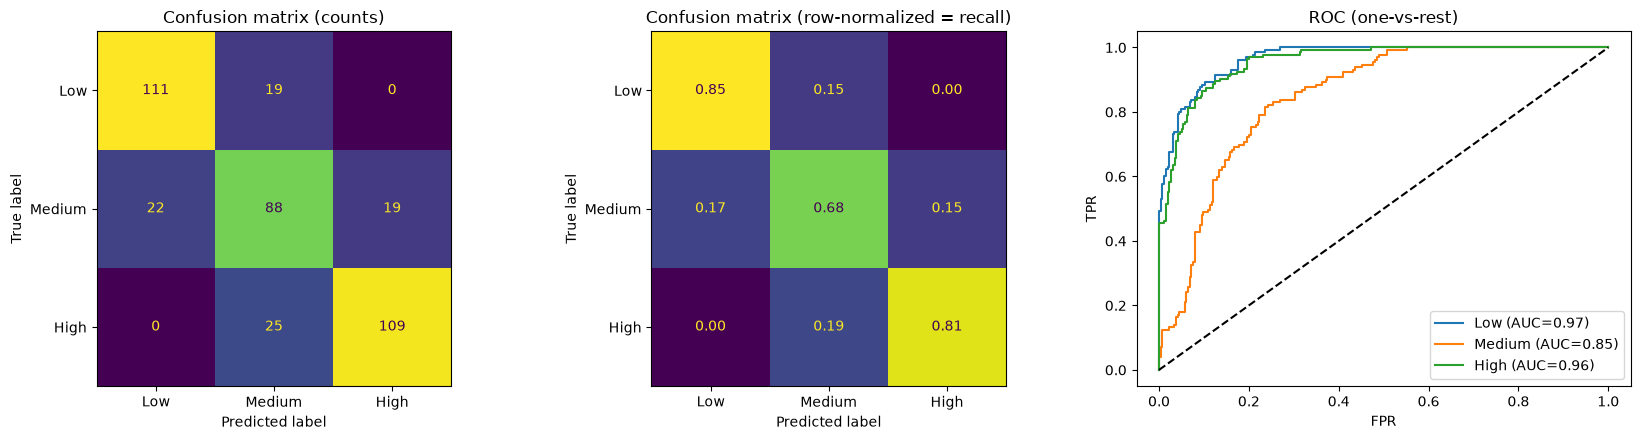

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=RISK_ORDER).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize="true"), display_labels=RISK_ORDER).plot(
    ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalized = recall)")

y_bin = label_binarize(y_test, classes=[0, 1, 2])
for i, risk in enumerate(RISK_ORDER):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    axes[2].plot(fpr, tpr, label=f"{risk} (AUC={roc_auc_score(y_bin[:, i], proba[:, i]):.2f})")
axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set_title("ROC (one-vs-rest)")
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].legend()
plt.tight_layout()
plt.show()

In [12]:
labels = dict(enumerate(RISK_ORDER))
errors = X_test.assign(
    true=y_test.map(labels),
    pred=pd.Series(pred, index=y_test.index).map(labels),
    confidence=proba.max(axis=1),
)
errors["wrong"] = errors["true"] != errors["pred"]

print("Errors:", errors["wrong"].sum(), "/", len(errors))
print("\nError rate per true class:\n", errors.groupby("true")["wrong"].mean().reindex(RISK_ORDER).round(3))

dist = np.abs(y_test.values - pred)
print("\nAdjacent errors (Low<->Medium, Medium<->High):", (dist == 1).sum())
print("Extreme errors (Low<->High):", (dist == 2).sum())

print("\nMean confidence of the predicted class:\n", errors.groupby("wrong")["confidence"].mean().round(3))

Errors: 85 / 393

Error rate per true class:
 true
Low       0.146
Medium    0.318
High      0.187
Name: wrong, dtype: float64

Adjacent errors (Low<->Medium, Medium<->High): 85
Extreme errors (Low<->High): 0

Mean confidence of the predicted class:
 wrong
False    0.794
True     0.652
Name: confidence, dtype: float64


In [13]:
numeric_cols, _ = get_column_types(X_test)
errors.groupby("wrong")[numeric_cols].mean().T.round(2)

wrong,False,True
Age,21.08,20.92
Year_of_Study,2.60,2.74
Sleep_Hours,6.78,6.61
Study_Hours_Per_Week,19.79,20.23
GPA,2.56,2.52
Social_Media_Hours,6.03,6.01
Screen_Time_Hours,8.54,8.64
Financial_Stress,5.86,5.75
Family_Support,6.73,6.31
Attendance_Rate,84.85,85.09


In [14]:
imp = permutation_importance(best_pipeline, X_test, y_test, scoring=SCORING, n_repeats=10,
                             random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).round(3)

Sleep_Hours                       0.266
Financial_Stress                  0.138
Previous_Mental_Health_History    0.114
Family_Support                    0.113
Physical_Activity                 0.093
GPA                               0.057
Diet_Quality                      0.024
Part_Time_Job                     0.018
Study_Hours_Per_Week              0.014
Social_Media_Hours                0.014
Attendance_Rate                   0.004
Screen_Time_Hours                 0.002
Year_of_Study                     0.002
Age                               0.001
Gender                           -0.007
dtype: float64

In [15]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_pipeline, "../models/best_pipeline.joblib")

loaded = joblib.load("../models/best_pipeline.joblib")
assert (loaded.predict(X_test) == pred).all()
print("Reloaded pipeline gives identical predictions")
loaded.predict(X_test.iloc[[0]])   

Reloaded pipeline gives identical predictions


array([2])

In [16]:
with tempfile.TemporaryDirectory() as tmp:
    dag = tune_models(X_train, X_test, y_train, y_test, os.path.join(tmp, "m.joblib"))

assert dag["best_model"] == best_name
assert abs(dag["cv_f1"][best_name] - tuned[best_name].best_score_) < 1e-9
assert abs(dag["test"]["f1"] - f1_score(y_test, pred, average="macro")) < 1e-9
print("tune_models() == notebook results")

tune_models() == notebook results
